In [1]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

model_path = r"C:\Users\usER\Downloads\1512427\converted_images_split\VGG16_Brain tumor_Classification.h5"

model = tf.keras.models.load_model(model_path)

print("Model loaded successfully.")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

print("\nModel layers:")
for i, layer in enumerate(model.layers):
    print(i, "->", layer.name, "->", layer.__class__.__name__)

C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Model loaded successfully.
Input shape: (None, 224, 224, 3)
Output shape: (None, 3)

Model layers:
0 -> input_layer_3 -> InputLayer
1 -> block1_conv1 -> Conv2D
2 -> block1_conv2 -> Conv2D
3 -> block1_pool -> MaxPooling2D
4 -> block2_conv1 -> Conv2D
5 -> block2_conv2 -> Conv2D
6 -> block2_pool -> MaxPooling2D
7 -> block3_conv1 -> Conv2D
8 -> block3_conv2 -> Conv2D
9 -> block3_conv3 -> Conv2D
10 -> block3_pool -> MaxPooling2D
11 -> block4_conv1 -> Conv2D
12 -> block4_conv2 -> Conv2D
13 -> block4_conv3 -> Conv2D
14 -> block4_pool -> MaxPooling2D
15 -> block5_conv1 -> Conv2D
16 -> block5_conv2 -> Conv2D
17 -> block5_conv3 -> Conv2D
18 -> block5_pool -> MaxPooling2D
19 -> flatten_2 -> Flatten
20 -> dense_5 -> Dense
21 -> dropout_3 -> Dropout
22 -> dense_6 -> Dense


In [2]:
target_layer = model.get_layer("block5_conv3")

print("Grad-CAM target layer:", target_layer.name)
print("Layer type:", target_layer.__class__.__name__)
print("Number of filters:", target_layer.filters)

# Check the actual output tensor shape
print("Output tensor shape:", target_layer.output.shape)

Grad-CAM target layer: block5_conv3
Layer type: Conv2D
Number of filters: 512
Output tensor shape: (None, 14, 14, 512)


In [4]:
image_path = r"C:\Users\usER\Downloads\1512427\converted_images_split\test\glioma\891.jpg"

def preprocess_image(path):

    img = tf.keras.preprocessing.image.load_img(
        path,
        target_size=(224, 224)
    )

    img = tf.keras.preprocessing.image.img_to_array(img)

    img = np.expand_dims(img, axis=0)

    img = img / 255.0

    return img


img_array = preprocess_image(image_path)

print("Image prepared successfully.")
print("Image shape:", img_array.shape)
print("Minimum pixel value:", img_array.min())
print("Maximum pixel value:", img_array.max())

Image prepared successfully.
Image shape: (1, 224, 224, 3)
Minimum pixel value: 0.0
Maximum pixel value: 0.972549


In [5]:
prediction = model.predict(img_array, verbose=0)

print("Raw prediction:", prediction)
print("Prediction shape:", prediction.shape)

predicted_index = np.argmax(prediction[0])
confidence = float(prediction[0][predicted_index])

print("Predicted class index:", predicted_index)
print("Confidence:", confidence)

Raw prediction: [[9.8576051e-01 1.4179404e-02 6.0082388e-05]]
Prediction shape: (1, 3)
Predicted class index: 0
Confidence: 0.985760509967804


In [6]:
import os

test_dir = r"C:\Users\usER\Downloads\1512427\converted_images_split\test"

class_names = sorted([
    folder for folder in os.listdir(test_dir)
    if os.path.isdir(os.path.join(test_dir, folder))
])

print("Class names in alphabetical order:")
for i, class_name in enumerate(class_names):
    print(i, "->", class_name)

print("\nModel predicted index:", predicted_index)
print("Corresponding class:", class_names[predicted_index])

Class names in alphabetical order:
0 -> glioma
1 -> meningioma
2 -> pituitary

Model predicted index: 0
Corresponding class: glioma


In [7]:
grad_model = tf.keras.models.Model(
    inputs=model.inputs,
    outputs=[
        target_layer.output,
        model.output
    ]
)

with tf.GradientTape() as tape:

    conv_outputs, predictions = grad_model(
        img_array,
        training=False
    )

    # Target the predicted class: pituitary (index 2)
    target = predictions[:, predicted_index]

grads = tape.gradient(
    target,
    conv_outputs
)

print("Target layer output shape:", conv_outputs.shape)
print("Prediction shape:", predictions.shape)
print("Target class index:", predicted_index)
print("Target class:", class_names[predicted_index])
print("Target probability:", float(target[0]))

print("\nGradient shape:", grads.shape)
print("Gradient minimum:", float(tf.reduce_min(grads)))
print("Gradient maximum:", float(tf.reduce_max(grads)))
print("Gradient mean:", float(tf.reduce_mean(grads)))
print("Gradient absolute mean:", float(tf.reduce_mean(tf.abs(grads))))

Target layer output shape: (1, 14, 14, 512)
Prediction shape: (1, 3)
Target class index: 0
Target class: glioma
Target probability: 0.985760509967804

Gradient shape: (1, 14, 14, 512)
Gradient minimum: -0.002874628873541951
Gradient maximum: 0.00279679661616683
Gradient mean: 1.935757609317079e-06
Gradient absolute mean: 0.00010454488074174151


In [8]:
# Global average pooling of gradients
pooled_grads = tf.reduce_mean(
    grads,
    axis=(0, 1, 2)
)

# Remove batch dimension from feature maps
conv_outputs = conv_outputs[0]

# Weighted combination of feature maps
heatmap = tf.reduce_sum(
    conv_outputs * pooled_grads,
    axis=-1
)

# Keep positive contributions only
heatmap = tf.maximum(
    heatmap,
    0
)

# Normalize heatmap to [0, 1]
max_val = tf.reduce_max(heatmap)

heatmap = tf.where(
    max_val > 0,
    heatmap / max_val,
    tf.zeros_like(heatmap)
)

heatmap = heatmap.numpy()

print("Grad-CAM generated successfully.")
print("Heatmap shape:", heatmap.shape)
print("Heatmap minimum:", heatmap.min())
print("Heatmap maximum:", heatmap.max())
print("Heatmap mean:", heatmap.mean())

Grad-CAM generated successfully.
Heatmap shape: (14, 14)
Heatmap minimum: 0.0
Heatmap maximum: 1.0
Heatmap mean: 0.2191625


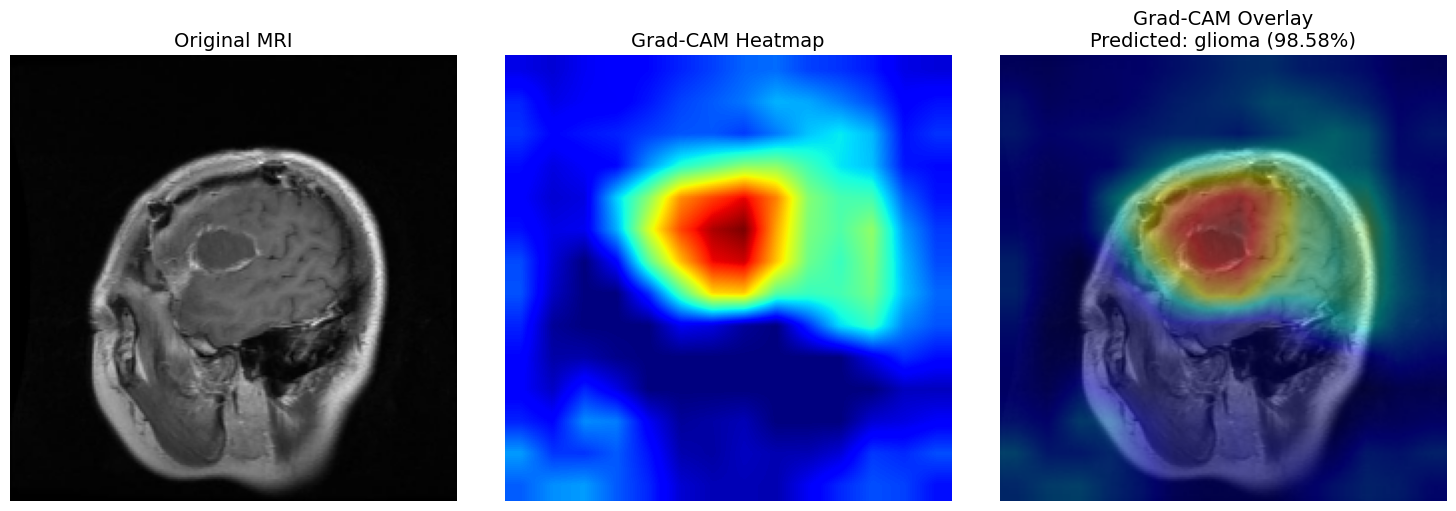

In [9]:
def show_gradcam(image_path, heatmap, predicted_class, confidence):

    # Load original MRI
    original = cv2.imread(image_path)
    original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    original = cv2.resize(original, (224, 224))

    # Resize Grad-CAM heatmap
    heatmap_resized = cv2.resize(
        heatmap,
        (224, 224),
        interpolation=cv2.INTER_LINEAR
    )

    # Convert heatmap to 8-bit
    heatmap_uint8 = np.uint8(255 * heatmap_resized)

    # Apply JET colormap
    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    # Create overlay
    overlay = cv2.addWeighted(
        original,
        0.6,
        heatmap_color,
        0.4,
        0
    )

    # Create figure
    plt.figure(figsize=(15, 5))

    # Original MRI
    plt.subplot(1, 3, 1)
    plt.imshow(original)
    plt.title("Original MRI", fontsize=14)
    plt.axis("off")

    # Grad-CAM Heatmap
    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title("Grad-CAM Heatmap", fontsize=14)
    plt.axis("off")

    # Grad-CAM Overlay
    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.title(
        f"Grad-CAM Overlay\n"
        f"Predicted: {predicted_class} ({confidence:.2%})",
        fontsize=14
    )
    plt.axis("off")

    plt.tight_layout()
    plt.show()


show_gradcam(
    image_path,
    heatmap,
    class_names[predicted_index],
    confidence
)

In [ ]:
meningioma

In [10]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

model_path = r"C:\Users\usER\Downloads\1512427\converted_images_split\VGG16_Brain tumor_Classification.h5"

model = tf.keras.models.load_model(model_path)

print("Model loaded successfully.")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

print("\nModel layers:")
for i, layer in enumerate(model.layers):
    print(i, "->", layer.name, "->", layer.__class__.__name__)

Model loaded successfully.
Input shape: (None, 224, 224, 3)
Output shape: (None, 3)

Model layers:
0 -> input_layer_3 -> InputLayer
1 -> block1_conv1 -> Conv2D
2 -> block1_conv2 -> Conv2D
3 -> block1_pool -> MaxPooling2D
4 -> block2_conv1 -> Conv2D
5 -> block2_conv2 -> Conv2D
6 -> block2_pool -> MaxPooling2D
7 -> block3_conv1 -> Conv2D
8 -> block3_conv2 -> Conv2D
9 -> block3_conv3 -> Conv2D
10 -> block3_pool -> MaxPooling2D
11 -> block4_conv1 -> Conv2D
12 -> block4_conv2 -> Conv2D
13 -> block4_conv3 -> Conv2D
14 -> block4_pool -> MaxPooling2D
15 -> block5_conv1 -> Conv2D
16 -> block5_conv2 -> Conv2D
17 -> block5_conv3 -> Conv2D
18 -> block5_pool -> MaxPooling2D
19 -> flatten_2 -> Flatten
20 -> dense_5 -> Dense
21 -> dropout_3 -> Dropout
22 -> dense_6 -> Dense


In [11]:
target_layer = model.get_layer("block5_conv3")

print("Grad-CAM target layer:", target_layer.name)
print("Layer type:", target_layer.__class__.__name__)
print("Number of filters:", target_layer.filters)

# Check the actual output tensor shape
print("Output tensor shape:", target_layer.output.shape)

Grad-CAM target layer: block5_conv3
Layer type: Conv2D
Number of filters: 512
Output tensor shape: (None, 14, 14, 512)


In [16]:
image_path = r"C:\Users\usER\Downloads\1512427\converted_images_split\train\meningioma\10.jpg"

def preprocess_image(path):

    img = tf.keras.preprocessing.image.load_img(
        path,
        target_size=(224, 224)
    )

    img = tf.keras.preprocessing.image.img_to_array(img)

    img = np.expand_dims(img, axis=0)

    img = img / 255.0

    return img


img_array = preprocess_image(image_path)

print("Image prepared successfully.")
print("Image shape:", img_array.shape)
print("Minimum pixel value:", img_array.min())
print("Maximum pixel value:", img_array.max())

Image prepared successfully.
Image shape: (1, 224, 224, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [17]:
prediction = model.predict(img_array, verbose=0)

print("Raw prediction:", prediction)
print("Prediction shape:", prediction.shape)

predicted_index = np.argmax(prediction[0])
confidence = float(prediction[0][predicted_index])

print("Predicted class index:", predicted_index)
print("Confidence:", confidence)

Raw prediction: [[1.0357224e-02 9.8938328e-01 2.5943492e-04]]
Prediction shape: (1, 3)
Predicted class index: 1
Confidence: 0.9893832802772522


In [18]:
import os

test_dir = r"C:\Users\usER\Downloads\1512427\converted_images_split\test"

class_names = sorted([
    folder for folder in os.listdir(test_dir)
    if os.path.isdir(os.path.join(test_dir, folder))
])

print("Class names in alphabetical order:")
for i, class_name in enumerate(class_names):
    print(i, "->", class_name)

print("\nModel predicted index:", predicted_index)
print("Corresponding class:", class_names[predicted_index])

Class names in alphabetical order:
0 -> glioma
1 -> meningioma
2 -> pituitary

Model predicted index: 1
Corresponding class: meningioma


In [19]:
grad_model = tf.keras.models.Model(
    inputs=model.inputs,
    outputs=[
        target_layer.output,
        model.output
    ]
)

with tf.GradientTape() as tape:

    conv_outputs, predictions = grad_model(
        img_array,
        training=False
    )

    # Target the predicted class: pituitary (index 2)
    target = predictions[:, predicted_index]

grads = tape.gradient(
    target,
    conv_outputs
)

print("Target layer output shape:", conv_outputs.shape)
print("Prediction shape:", predictions.shape)
print("Target class index:", predicted_index)
print("Target class:", class_names[predicted_index])
print("Target probability:", float(target[0]))

print("\nGradient shape:", grads.shape)
print("Gradient minimum:", float(tf.reduce_min(grads)))
print("Gradient maximum:", float(tf.reduce_max(grads)))
print("Gradient mean:", float(tf.reduce_mean(grads)))
print("Gradient absolute mean:", float(tf.reduce_mean(tf.abs(grads))))

Target layer output shape: (1, 14, 14, 512)
Prediction shape: (1, 3)
Target class index: 1
Target class: meningioma
Target probability: 0.9893832802772522

Gradient shape: (1, 14, 14, 512)
Gradient minimum: -0.001976344734430313
Gradient maximum: 0.0020071114413440228
Gradient mean: -1.4929572671462665e-06
Gradient absolute mean: 7.419818575726822e-05


In [20]:
# Global average pooling of gradients
pooled_grads = tf.reduce_mean(
    grads,
    axis=(0, 1, 2)
)

# Remove batch dimension from feature maps
conv_outputs = conv_outputs[0]

# Weighted combination of feature maps
heatmap = tf.reduce_sum(
    conv_outputs * pooled_grads,
    axis=-1
)

# Keep positive contributions only
heatmap = tf.maximum(
    heatmap,
    0
)

# Normalize heatmap to [0, 1]
max_val = tf.reduce_max(heatmap)

heatmap = tf.where(
    max_val > 0,
    heatmap / max_val,
    tf.zeros_like(heatmap)
)

heatmap = heatmap.numpy()

print("Grad-CAM generated successfully.")
print("Heatmap shape:", heatmap.shape)
print("Heatmap minimum:", heatmap.min())
print("Heatmap maximum:", heatmap.max())
print("Heatmap mean:", heatmap.mean())

Grad-CAM generated successfully.
Heatmap shape: (14, 14)
Heatmap minimum: 0.0
Heatmap maximum: 1.0
Heatmap mean: 0.026187077


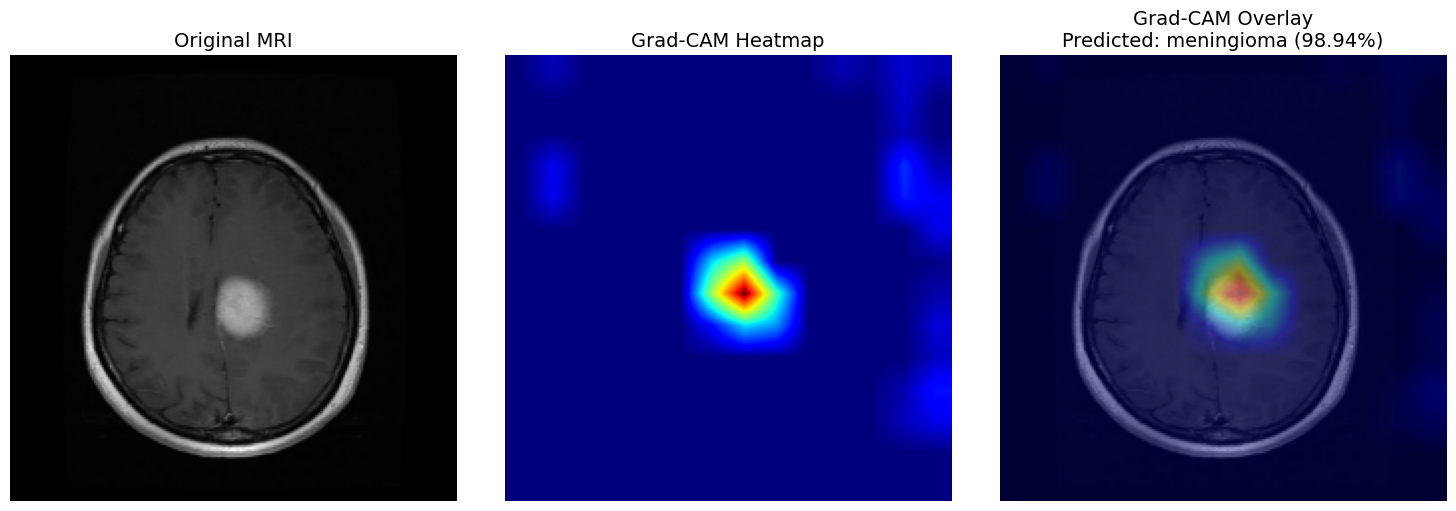

In [21]:
def show_gradcam(image_path, heatmap, predicted_class, confidence):

    # Load original MRI
    original = cv2.imread(image_path)
    original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    original = cv2.resize(original, (224, 224))

    # Resize Grad-CAM heatmap
    heatmap_resized = cv2.resize(
        heatmap,
        (224, 224),
        interpolation=cv2.INTER_LINEAR
    )

    # Convert heatmap to 8-bit
    heatmap_uint8 = np.uint8(255 * heatmap_resized)

    # Apply JET colormap
    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    # Create overlay
    overlay = cv2.addWeighted(
        original,
        0.6,
        heatmap_color,
        0.4,
        0
    )

    # Create figure
    plt.figure(figsize=(15, 5))

    # Original MRI
    plt.subplot(1, 3, 1)
    plt.imshow(original)
    plt.title("Original MRI", fontsize=14)
    plt.axis("off")

    # Grad-CAM Heatmap
    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title("Grad-CAM Heatmap", fontsize=14)
    plt.axis("off")

    # Grad-CAM Overlay
    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.title(
        f"Grad-CAM Overlay\n"
        f"Predicted: {predicted_class} ({confidence:.2%})",
        fontsize=14
    )
    plt.axis("off")

    plt.tight_layout()
    plt.show()


show_gradcam(
    image_path,
    heatmap,
    class_names[predicted_index],
    confidence
)

In [22]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

model_path = r"C:\Users\usER\Downloads\1512427\converted_images_split\VGG16_Brain tumor_Classification.h5"

model = tf.keras.models.load_model(model_path)

print("Model loaded successfully.")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

print("\nModel layers:")
for i, layer in enumerate(model.layers):
    print(i, "->", layer.name, "->", layer.__class__.__name__)

Model loaded successfully.
Input shape: (None, 224, 224, 3)
Output shape: (None, 3)

Model layers:
0 -> input_layer_3 -> InputLayer
1 -> block1_conv1 -> Conv2D
2 -> block1_conv2 -> Conv2D
3 -> block1_pool -> MaxPooling2D
4 -> block2_conv1 -> Conv2D
5 -> block2_conv2 -> Conv2D
6 -> block2_pool -> MaxPooling2D
7 -> block3_conv1 -> Conv2D
8 -> block3_conv2 -> Conv2D
9 -> block3_conv3 -> Conv2D
10 -> block3_pool -> MaxPooling2D
11 -> block4_conv1 -> Conv2D
12 -> block4_conv2 -> Conv2D
13 -> block4_conv3 -> Conv2D
14 -> block4_pool -> MaxPooling2D
15 -> block5_conv1 -> Conv2D
16 -> block5_conv2 -> Conv2D
17 -> block5_conv3 -> Conv2D
18 -> block5_pool -> MaxPooling2D
19 -> flatten_2 -> Flatten
20 -> dense_5 -> Dense
21 -> dropout_3 -> Dropout
22 -> dense_6 -> Dense


In [23]:
target_layer = model.get_layer("block5_conv3")

print("Grad-CAM target layer:", target_layer.name)
print("Layer type:", target_layer.__class__.__name__)
print("Number of filters:", target_layer.filters)

# Check the actual output tensor shape
print("Output tensor shape:", target_layer.output.shape)

Grad-CAM target layer: block5_conv3
Layer type: Conv2D
Number of filters: 512
Output tensor shape: (None, 14, 14, 512)


In [24]:
image_path = r"C:\Users\usER\Downloads\1512427\converted_images_split\test\pituitary\1735.jpg"

def preprocess_image(path):

    img = tf.keras.preprocessing.image.load_img(
        path,
        target_size=(224, 224)
    )

    img = tf.keras.preprocessing.image.img_to_array(img)

    img = np.expand_dims(img, axis=0)

    img = img / 255.0

    return img


img_array = preprocess_image(image_path)

print("Image prepared successfully.")
print("Image shape:", img_array.shape)
print("Minimum pixel value:", img_array.min())
print("Maximum pixel value:", img_array.max())

Image prepared successfully.
Image shape: (1, 224, 224, 3)
Minimum pixel value: 0.0
Maximum pixel value: 0.9843137


In [25]:
prediction = model.predict(img_array, verbose=0)

print("Raw prediction:", prediction)
print("Prediction shape:", prediction.shape)

predicted_index = np.argmax(prediction[0])
confidence = float(prediction[0][predicted_index])

print("Predicted class index:", predicted_index)
print("Confidence:", confidence)

Raw prediction: [[8.8583738e-06 2.5130113e-05 9.9996603e-01]]
Prediction shape: (1, 3)
Predicted class index: 2
Confidence: 0.999966025352478


In [26]:
import os

test_dir = r"C:\Users\usER\Downloads\1512427\converted_images_split\test"

class_names = sorted([
    folder for folder in os.listdir(test_dir)
    if os.path.isdir(os.path.join(test_dir, folder))
])

print("Class names in alphabetical order:")
for i, class_name in enumerate(class_names):
    print(i, "->", class_name)

print("\nModel predicted index:", predicted_index)
print("Corresponding class:", class_names[predicted_index])

Class names in alphabetical order:
0 -> glioma
1 -> meningioma
2 -> pituitary

Model predicted index: 2
Corresponding class: pituitary


In [27]:
grad_model = tf.keras.models.Model(
    inputs=model.inputs,
    outputs=[
        target_layer.output,
        model.output
    ]
)

with tf.GradientTape() as tape:

    conv_outputs, predictions = grad_model(
        img_array,
        training=False
    )

    # Target the predicted class: pituitary (index 2)
    target = predictions[:, predicted_index]

grads = tape.gradient(
    target,
    conv_outputs
)

print("Target layer output shape:", conv_outputs.shape)
print("Prediction shape:", predictions.shape)
print("Target class index:", predicted_index)
print("Target class:", class_names[predicted_index])
print("Target probability:", float(target[0]))

print("\nGradient shape:", grads.shape)
print("Gradient minimum:", float(tf.reduce_min(grads)))
print("Gradient maximum:", float(tf.reduce_max(grads)))
print("Gradient mean:", float(tf.reduce_mean(grads)))
print("Gradient absolute mean:", float(tf.reduce_mean(tf.abs(grads))))

Target layer output shape: (1, 14, 14, 512)
Prediction shape: (1, 3)
Target class index: 2
Target class: pituitary
Target probability: 0.999966025352478

Gradient shape: (1, 14, 14, 512)
Gradient minimum: -3.191421455994714e-06
Gradient maximum: 5.022647656005574e-06
Gradient mean: 1.9972732800965787e-08
Gradient absolute mean: 1.558184976602206e-07


In [28]:
# Global average pooling of gradients
pooled_grads = tf.reduce_mean(
    grads,
    axis=(0, 1, 2)
)

# Remove batch dimension from feature maps
conv_outputs = conv_outputs[0]

# Weighted combination of feature maps
heatmap = tf.reduce_sum(
    conv_outputs * pooled_grads,
    axis=-1
)

# Keep positive contributions only
heatmap = tf.maximum(
    heatmap,
    0
)

# Normalize heatmap to [0, 1]
max_val = tf.reduce_max(heatmap)

heatmap = tf.where(
    max_val > 0,
    heatmap / max_val,
    tf.zeros_like(heatmap)
)

heatmap = heatmap.numpy()

print("Grad-CAM generated successfully.")
print("Heatmap shape:", heatmap.shape)
print("Heatmap minimum:", heatmap.min())
print("Heatmap maximum:", heatmap.max())
print("Heatmap mean:", heatmap.mean())

Grad-CAM generated successfully.
Heatmap shape: (14, 14)
Heatmap minimum: 0.0
Heatmap maximum: 1.0
Heatmap mean: 0.371541


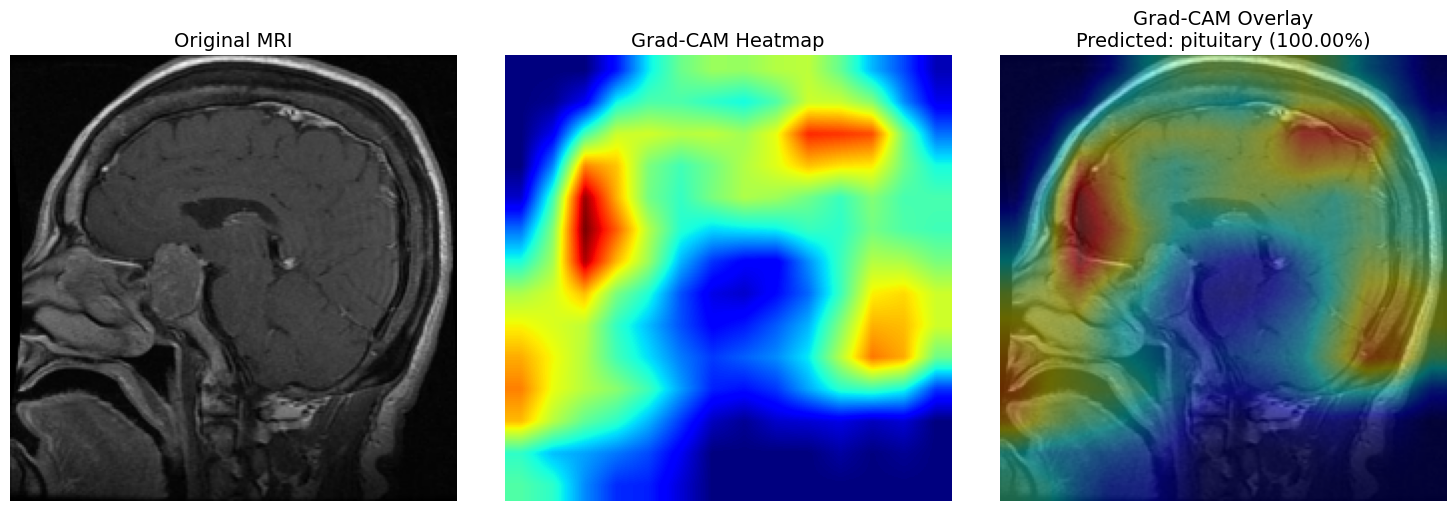

In [29]:
def show_gradcam(image_path, heatmap, predicted_class, confidence):

    # Load original MRI
    original = cv2.imread(image_path)
    original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    original = cv2.resize(original, (224, 224))

    # Resize Grad-CAM heatmap
    heatmap_resized = cv2.resize(
        heatmap,
        (224, 224),
        interpolation=cv2.INTER_LINEAR
    )

    # Convert heatmap to 8-bit
    heatmap_uint8 = np.uint8(255 * heatmap_resized)

    # Apply JET colormap
    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    # Create overlay
    overlay = cv2.addWeighted(
        original,
        0.6,
        heatmap_color,
        0.4,
        0
    )

    # Create figure
    plt.figure(figsize=(15, 5))

    # Original MRI
    plt.subplot(1, 3, 1)
    plt.imshow(original)
    plt.title("Original MRI", fontsize=14)
    plt.axis("off")

    # Grad-CAM Heatmap
    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title("Grad-CAM Heatmap", fontsize=14)
    plt.axis("off")

    # Grad-CAM Overlay
    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.title(
        f"Grad-CAM Overlay\n"
        f"Predicted: {predicted_class} ({confidence:.2%})",
        fontsize=14
    )
    plt.axis("off")

    plt.tight_layout()
    plt.show()


show_gradcam(
    image_path,
    heatmap,
    class_names[predicted_index],
    confidence
)